<a href="https://colab.research.google.com/github/gyeongee/TIL/blob/main/%EC%84%A0%ED%98%95%ED%9A%8C%EA%B7%80_%EC%8B%A4%EC%8A%B5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [74]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### 목표 : 선형회귀 구현
- 데이터 가져오기(당뇨병 진행도를 예측하는 데이터)
  - 특성데이터 : 442명의 대상 당뇨병 환자 데이터(검사결과)
  - 라벨데이터 : 1년 뒤 측정한 당뇨병의 진행률
- 데이터셋 구조
 - age : 나이
 - sex : 성별
 - bmi : bmi 지수
 - bp : 평균혈압
 - s1~s6 : 6종류의 혈액검사수치값

In [75]:
from sklearn.datasets import load_diabetes
house = load_diabetes()

In [76]:
df=pd.DataFrame(data=house.data,columns=house.feature_names)
df['target']=house.target
df.head(3)

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0


In [77]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 442 entries, 0 to 441
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   age     442 non-null    float64
 1   sex     442 non-null    float64
 2   bmi     442 non-null    float64
 3   bp      442 non-null    float64
 4   s1      442 non-null    float64
 5   s2      442 non-null    float64
 6   s3      442 non-null    float64
 7   s4      442 non-null    float64
 8   s5      442 non-null    float64
 9   s6      442 non-null    float64
 10  target  442 non-null    float64
dtypes: float64(11)
memory usage: 38.1 KB


속성의 분포와 속성 사이의 선형적 관계 유무를 파악하기 위해서 페어 플롯을 그려봅니다.

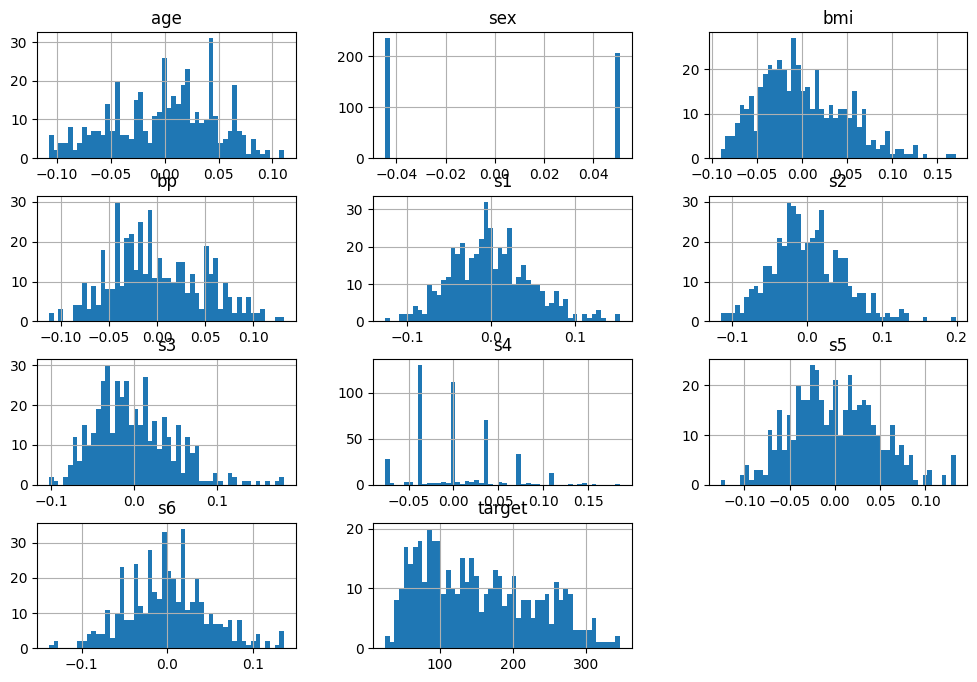

In [78]:
# 판다스 자체에서도 plt와 호환해서 시각화할 수 있는 기능
df.hist(bins=50, figsize=(12,8))
plt.show()

target 속성과 선형적 관계를 띄는 속성을 추려 내어 다시 페어 플롯을 그려봅시다.

학습 코드 구현

In [79]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

In [80]:
# Numpy 데이터를 파이토치 실수형 텐서로 변환
data=torch.from_numpy(df.values).float()
data.shape

torch.Size([442, 11])

In [81]:
# 데이터를 입력 x와 출력 y로 나누기

# 모든 행, 마지막 열을 제외한 컬럼드만 담아주기
x=data[:,:-1]
# 모든 행,마지막 열만 담아주기
y=data[:,-1:]
print(x.shape,y.shape)

torch.Size([442, 10]) torch.Size([442, 1])


In [82]:
# 학습에 필요한 설정값 정하기
n_epochs=200000
learning_rate=1e-3
print_interval=20000

In [83]:
# 텐서 x의 마지막 차원의 크기를 선형 계층의 입력 크기로 주고, 텐서 y의 마지막 차원의 크기를 선형 계층의 출력 크기로 줍니다.
model=nn.Linear(x.size(-1),y.size(-1))
print(model)

Linear(in_features=10, out_features=1, bias=True)


In [84]:
# 옵티마이저 생성
optimizer=optim.SGD(model.parameters(),lr=learning_rate)
optimizer

SGD (
Parameter Group 0
    dampening: 0
    differentiable: False
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    momentum: 0
    nesterov: False
    weight_decay: 0
)

In [85]:
# 학습
from tqdm import tqdm
for i in tqdm(range(n_epochs)):
  # 순전파(forward)
  y_hat=model(x)
  loss=F.mse_loss(y_hat,y)

  # 역전파와 파라미터 갱신(backward & update)
  # 기울기 0으로 초기화
  optimizer.zero_grad()
  loss.backward()

  optimizer.step()

  if (i+1) % print_interval == 0:
    print('Epoch %d loss=%.4e'%(i+1,loss))

 10%|█         | 20519/200000 [00:07<01:09, 2592.01it/s]

Epoch 20000 loss=4.7709e+03


 20%|██        | 40513/200000 [00:15<00:59, 2696.98it/s]

Epoch 40000 loss=4.1415e+03


 30%|███       | 60390/200000 [00:23<00:58, 2377.90it/s]

Epoch 60000 loss=3.7792e+03


... (10 outputs left out)

 90%|█████████ | 180413/200000 [01:11<00:07, 2577.05it/s]

Epoch 180000 loss=3.1187e+03


100%|██████████| 200000/200000 [01:19<00:00, 2513.34it/s]

Epoch 200000 loss=3.0798e+03


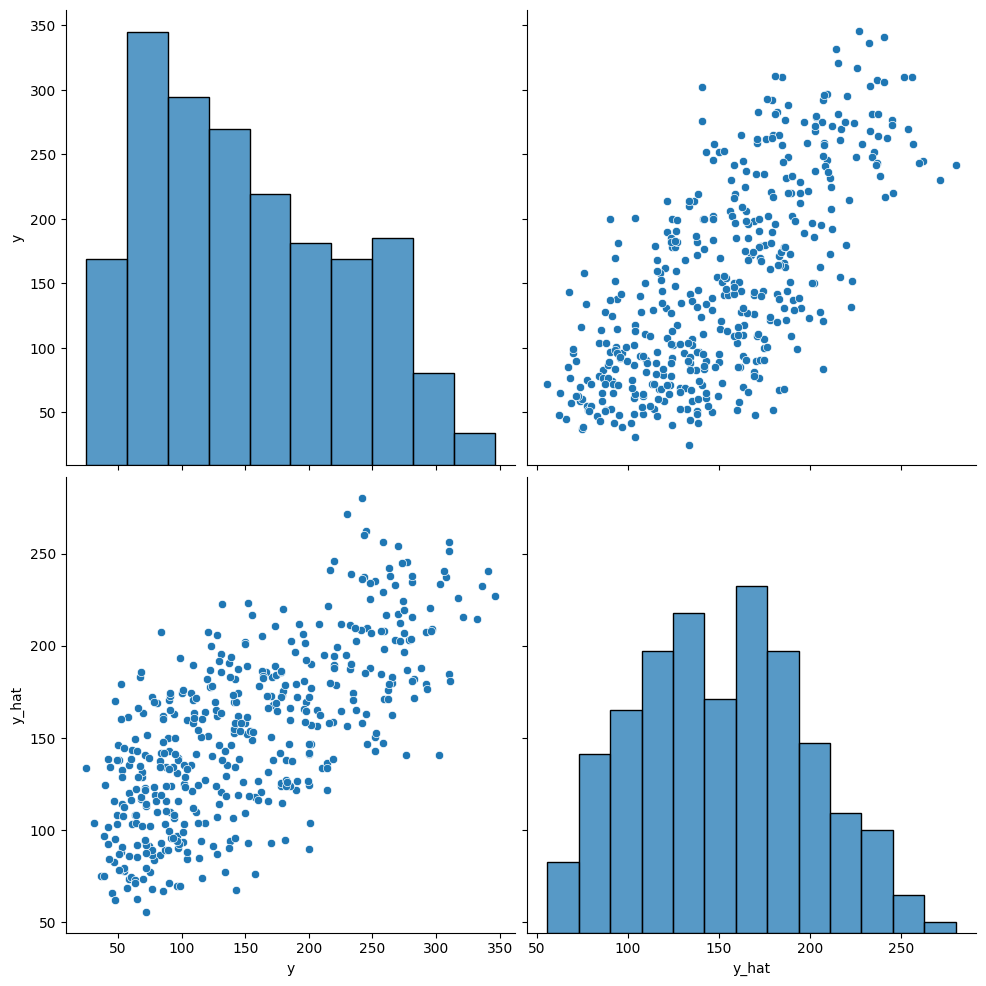

In [86]:
# 결과 확인
df=pd.DataFrame(torch.cat([y,y_hat],dim=1).detach_().numpy(),columns=["y","y_hat"])
sns.pairplot(df,height=5)
plt.show()